# Student Performance Analyzer
### Software Lab Case Study | Python, NumPy, pandas, Matplotlib

**Problem statement:** Manually reviewing student marks, attendance, and study hours can take time. This project analyzes a sample academic dataset to summarize performance, compare subjects, identify students who may benefit from support, and visualize patterns.

**Objectives**
- Load student records from a CSV file.
- Calculate total marks, average marks, percentages, and performance categories.
- Analyze subject averages and attendance using pandas and NumPy.
- Visualize findings using Matplotlib.
- Save an analysis report to a text file.

> The included dataset is fictional and intended only for demonstration. Observed patterns do not prove cause and effect.

In [6]:
from pathlib import Path

print(Path.cwd())
print(Path("data/student_data.csv").exists())

C:\Users\Tiya\OneDrive\Desktop\projects\Student_Performance_Analyzer_Project\Student_Performance_Analyzer
True


## 1. Import libraries and load the dataset

In [7]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("data/student_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("student_data.csv")

df = pd.read_csv(DATA_PATH)
df.head()

,Student_ID,Name,Python,Maths,Networks,Attendance,Study_Hours
0,S101,Aditi,85,78,82,92,3.5
1,S102,Rohan,62,55,68,75,2.0
2,S103,Meera,91,88,90,96,4.0
3,S104,Arjun,45,39,52,61,1.5
4,S105,Neha,74,81,76,88,3.0


## 2. Understand the dataset

In [8]:
print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:", list(df.columns))
print("\nData types and non-empty values:")
df.info()

Dataset shape (rows, columns): (20, 7)

Column names: ['Student_ID', 'Name', 'Python', 'Maths', 'Networks', 'Attendance', 'Study_Hours']

Data types and non-empty values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   20 non-null     object 
 1   Name         20 non-null     object 
 2   Python       20 non-null     int64  
 3   Maths        20 non-null     int64  
 4   Networks     20 non-null     int64  
 5   Attendance   20 non-null     int64  
 6   Study_Hours  20 non-null     float64
dtypes: float64(1), int64(4), object(2)
memory usage: 1.2+ KB


In [11]:
print("Missing values per column:")
display(df.isnull().sum())
print("\nDescriptive statistics:")
display(df.describe())

Missing values per column:


Student_ID     0
Name           0
Python         0
Maths          0
Networks       0
Attendance     0
Study_Hours    0
dtype: int64


Descriptive statistics:


,Python,Maths,Networks,Attendance,Study_Hours
count,20.000000,20.000000,20.00000,20.000000,20.000000
mean,69.350000,68.650000,71.70000,80.850000,2.680000
std,16.607782,16.875005,15.02314,12.325733,1.024746
min,36.000000,39.000000,45.00000,58.000000,1.000000
25%,59.250000,56.500000,60.50000,73.000000,1.950000
50%,70.000000,72.500000,72.00000,81.500000,2.600000
75%,82.750000,81.750000,83.00000,91.250000,3.500000
max,94.000000,93.000000,94.00000,98.000000,4.500000


## 3. Core Python concepts: variables, operators, strings, lists, tuples, sets, and dictionaries

In [26]:
student_name = "Aditi"
python_marks = 85
maths_marks = 78
networks_marks = 82
maximum_marks_per_subject = 100

total_marks = python_marks + maths_marks + networks_marks
average_marks = total_marks / 3
percentage = (total_marks / (3 * maximum_marks_per_subject)) * 100

print(f"{student_name}'s total: {total_marks}/300")
print(f"Average: {average_marks:.2f}")
print(f"Percentage: {percentage:.1f}%")

clean_name = student_name.strip().title()
print("Clean name:", clean_name)

marks_list = [python_marks, maths_marks, networks_marks]
print("Marks list:", marks_list)

subjects = ("Python", "Maths", "Networks")
print("Subjects:", subjects)

subject_set = set(["Python", "Maths", "Python", "Networks"])
print("Unique subjects:", subject_set)

student_record = {
    "Student_ID": "S101",
    "Name": student_name,
    "Marks": marks_list,
    "Attendance": 92
}
print("Student dictionary:", student_record)

Aditi's total: 245/300
Average: 81.67
Percentage: 81.7%
Clean name: Aditi
Marks list: [85, 78, 82]
Subjects: ('Python', 'Maths', 'Networks')
Unique subjects: {'Networks', 'Maths', 'Python'}
Student dictionary: {'Student_ID': 'S101', 'Name': 'Aditi', 'Marks': [85, 78, 82], 'Attendance': 92}


## 4. Create reusable functions

In [25]:
def calculate_total(marks):
    return sum(marks)

def calculate_average(marks):
    return np.mean(marks)

def performance_category(average):
    if average >= 85:
        return "Excellent"
    elif average >= 70:
        return "Good"
    elif average >= 50:
        return "Needs Improvement"
    else:
        return "At Risk"

example_marks = [85, 78, 82]
example_average = calculate_average(example_marks)
print("Total:", calculate_total(example_marks))
print("Average:", round(example_average, 2))
print("Category:", performance_category(example_average))

Total: 245
Average: 81.67
Category: Good


## 5. Analyze the dataset with pandas and NumPy

In [15]:
subject_columns = ["Python", "Maths", "Networks"]

df["Total_Marks"] = df[subject_columns].sum(axis=1)
df["Average_Marks"] = df[subject_columns].mean(axis=1)
df["Percentage"] = (df["Total_Marks"] / (len(subject_columns) * 100)) * 100
df["Category"] = df["Average_Marks"].apply(performance_category)
df["Result"] = np.where((df[subject_columns] >= 35).all(axis=1), "Pass", "Fail")

display(df[["Student_ID", "Name"] + subject_columns + [
    "Total_Marks", "Average_Marks", "Percentage", "Attendance", "Category", "Result"
]].head(10))

,Student_ID,Name,Python,Maths,Networks,Total_Marks,Average_Marks,Percentage,Attendance,Category,Result
0,S101,Aditi,85,78,82,245,81.666667,81.666667,92,Good,Pass
1,S102,Rohan,62,55,68,185,61.666667,61.666667,75,Needs Improvement,Pass
2,S103,Meera,91,88,90,269,89.666667,89.666667,96,Excellent,Pass
3,S104,Arjun,45,39,52,136,45.333333,45.333333,61,At Risk,Pass
4,S105,Neha,74,81,76,231,77.000000,77.000000,88,Good,Pass
5,S106,Kabir,68,72,65,205,68.333333,68.333333,80,Needs Improvement,Pass
6,S107,Isha,88,93,86,267,89.000000,89.000000,94,Excellent,Pass
7,S108,Dev,57,49,61,167,55.666667,55.666667,70,Needs Improvement,Pass
8,S109,Sara,79,84,80,243,81.000000,81.000000,90,Good,Pass
9,S110,Om,36,42,45,123,41.000000,41.000000,58,At Risk,Pass


In [16]:
all_marks = df[subject_columns].to_numpy()
print("Overall mean mark:", round(np.mean(all_marks), 2))
print("Overall median mark:", round(np.median(all_marks), 2))
print("Standard deviation:", round(np.std(all_marks), 2))

subject_averages = df[subject_columns].mean().sort_values(ascending=False)
print("\nSubject-wise average marks:")
display(subject_averages.to_frame(name="Average Marks"))

print("\nPerformance category counts:")
display(df["Category"].value_counts().to_frame(name="Number of Students"))

Overall mean mark: 69.9
Overall median mark: 72.0
Standard deviation: 15.83

Subject-wise average marks:


,Average Marks
Networks,71.70
Python,69.35
Maths,68.65



Performance category counts:


,Number of Students
Category,
Needs Improvement,7
Good,6
Excellent,4
At Risk,3


## 6. Search and filter student records

In [17]:
def find_student(student_id, dataframe=df):
    # Find a student by ID; return a matching row or a helpful message.
    match = dataframe[dataframe["Student_ID"].astype(str).str.upper() == student_id.strip().upper()]
    if match.empty:
        print("No student found with ID:", student_id)
        return None
    return match

display(find_student("S103"))

low_attendance = df[df["Attendance"] < 75]
print("Students with attendance below 75%:")
display(low_attendance[["Student_ID", "Name", "Attendance", "Average_Marks"]])

,Student_ID,Name,Python,Maths,Networks,Attendance,Study_Hours,Total_Marks,Average_Marks,Percentage,Category,Result
2,S103,Meera,91,88,90,96,4.0,269,89.666667,89.666667,Excellent,Pass


Students with attendance below 75%:


,Student_ID,Name,Attendance,Average_Marks
3,S104,Arjun,61,45.333333
7,S108,Dev,70,55.666667
9,S110,Om,58,41.000000
13,S114,Kunal,68,54.333333
15,S116,Aarav,74,62.000000
17,S118,Yash,64,47.333333


## 7. Visualizations with Matplotlib

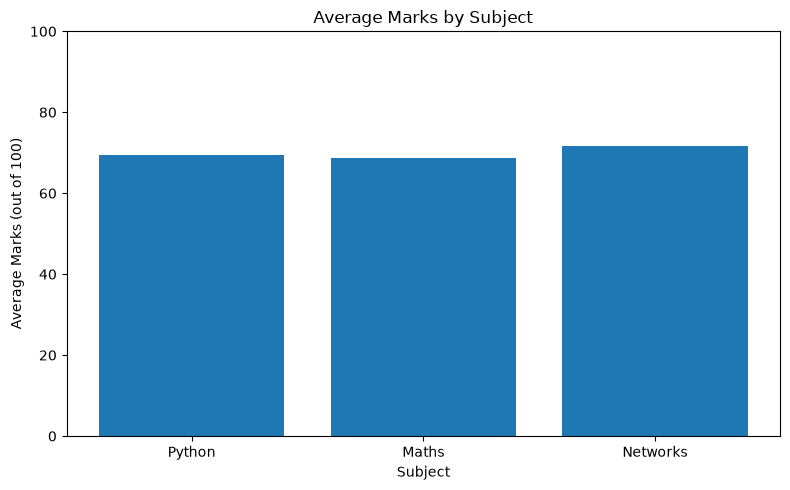

In [18]:
subject_averages = df[subject_columns].mean()
plt.figure(figsize=(8, 5))
plt.bar(subject_averages.index, subject_averages.values)
plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Marks (out of 100)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

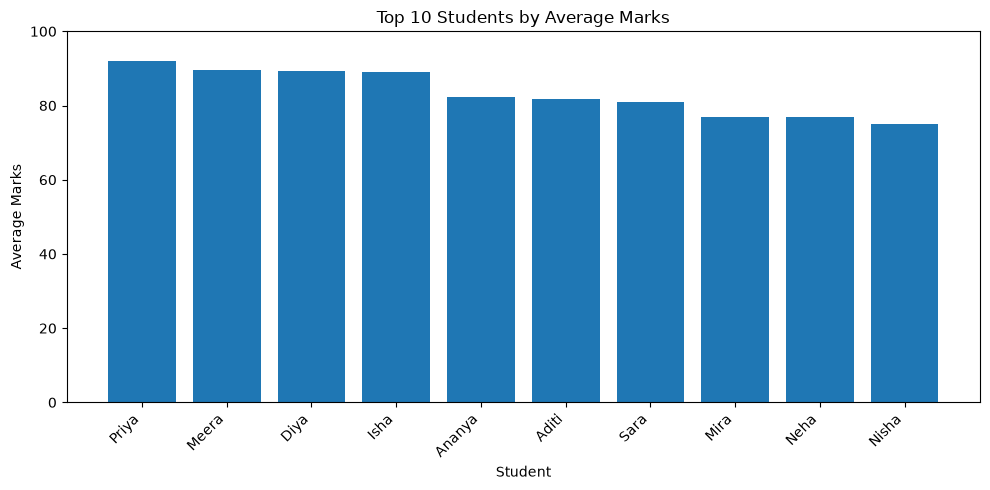

In [19]:
plot_df = df.sort_values("Average_Marks", ascending=False).head(10)
plt.figure(figsize=(10, 5))
plt.bar(plot_df["Name"], plot_df["Average_Marks"])
plt.title("Top 10 Students by Average Marks")
plt.xlabel("Student")
plt.ylabel("Average Marks")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

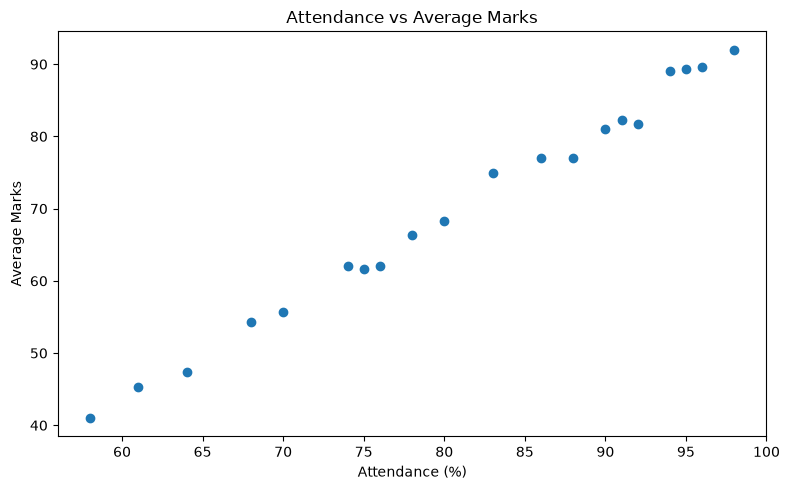

In [20]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Attendance"], df["Average_Marks"])
plt.title("Attendance vs Average Marks")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Marks")
plt.tight_layout()
plt.show()

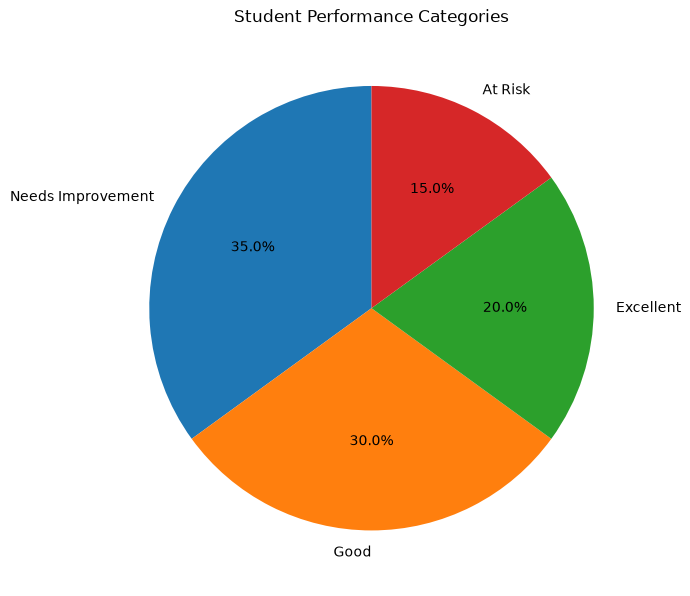

In [21]:
category_counts = df["Category"].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(category_counts.values, labels=category_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Student Performance Categories")
plt.tight_layout()
plt.show()

## 8. Generate and save a report

In [22]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

analyzed_csv = OUTPUT_DIR / "analyzed_student_data.csv"
df.to_csv(analyzed_csv, index=False)

top_student = df.loc[df["Average_Marks"].idxmax()]
lowest_subject = df[subject_columns].mean().idxmin()
pass_rate = (df["Result"] == "Pass").mean() * 100
low_attendance_count = int((df["Attendance"] < 75).sum())

report_lines = [
    "STUDENT PERFORMANCE ANALYZER — SUMMARY REPORT",
    "=" * 48,
    f"Number of students: {len(df)}",
    f"Overall average across subject marks: {df[subject_columns].to_numpy().mean():.2f}",
    f"Subject with lowest average: {lowest_subject} ({df[lowest_subject].mean():.2f})",
    f"Highest average: {top_student['Name']} ({top_student['Average_Marks']:.2f})",
    f"Pass rate (all subjects >= 35): {pass_rate:.1f}%",
    f"Students with attendance below 75%: {low_attendance_count}",
    "",
    "Note: The dataset is fictional. Patterns are descriptive and do not establish causation."
]
report_text = "\n".join(report_lines)

report_path = OUTPUT_DIR / "summary_report.txt"
report_path.write_text(report_text, encoding="utf-8")

print(report_text)
print("\nSaved analyzed data to:", analyzed_csv)
print("Saved summary report to:", report_path)

STUDENT PERFORMANCE ANALYZER — SUMMARY REPORT
Number of students: 20
Overall average across subject marks: 69.90
Subject with lowest average: Maths (68.65)
Highest average: Priya (92.00)
Pass rate (all subjects >= 35): 100.0%
Students with attendance below 75%: 6

Note: The dataset is fictional. Patterns are descriptive and do not establish causation.

Saved analyzed data to: outputs\analyzed_student_data.csv
Saved summary report to: outputs\summary_report.txt


## 9. Case study findings and limitations

In [23]:
print("CASE STUDY FINDINGS")
print("-------------------")
print(f"Lowest average subject: {df[subject_columns].mean().idxmin()}")
print(f"Highest average subject: {df[subject_columns].mean().idxmax()}")
print(f"Students needing attendance follow-up (<75%): {(df['Attendance'] < 75).sum()}")
print(f"Students in 'At Risk' category: {(df['Category'] == 'At Risk').sum()}")

correlation = df["Attendance"].corr(df["Average_Marks"])
print(f"Correlation between attendance and average marks: {correlation:.2f}")
print("Correlation describes association only; it does not prove that attendance causes marks to change.")

CASE STUDY FINDINGS
-------------------
Lowest average subject: Maths
Highest average subject: Networks
Students needing attendance follow-up (<75%): 6
Students in 'At Risk' category: 3
Correlation between attendance and average marks: 1.00
Correlation describes association only; it does not prove that attendance causes marks to change.


## 10. Conclusion

The Student Performance Analyzer demonstrates how a CSV dataset can be processed with core Python, NumPy, pandas, and Matplotlib. It calculates student-level metrics, summarizes subject performance, identifies records for follow-up, visualizes patterns, and saves outputs for later use.

**Limitations**
- The supplied dataset is fictional and small.
- Performance categories and pass thresholds are illustrative and should be adjusted to match institutional rules.
- Attendance and study hours are not proof of the cause of academic outcomes.
- The program is an educational analysis tool, not a substitute for teacher judgement.

## Viva revision: where each required topic appears

| Required topic | Demonstration |
|---|---|
| Variables | `student_name`, `total_marks`, `df` |
| Operators | `+`, `/`, `>=`, `<`, `==` |
| Strings | `.strip()`, `.title()`, `.str.upper()`, f-strings |
| Lists | `marks_list`, `subject_columns`, `report_lines` |
| Tuples | `subjects` |
| Sets | `subject_set` |
| Dictionaries | `student_record` |
| Functions | `calculate_total`, `calculate_average`, `performance_category`, `find_student` |
| Files | `pd.read_csv`, `to_csv`, `Path.write_text` |
| NumPy | `np.mean`, `np.median`, `np.std`, `np.where` |
| pandas | DataFrame, filtering, value counts, summary statistics |
| Matplotlib | Bar charts, scatter plot, pie chart |